# Forecasting Daily Emergency Medical Demand in New York City
## Capstone Assignment 20.1 – Initial Report and Exploratory Data Analysis

**Author:** Tiya Lee

### Research question
Can historical emergency demand data, weather, and calendar factors be used to predict **daily citywide emergency medical (911 EMS) incident volume in New York City** over the most recent three-plus years of normal, post-pandemic operations (January 2023 – September 2026)?

### Why this dataset
The Module 16 proposal targeted daily emergency department (ED) visit counts. The only public NYC ED-visit series (DOHMH syndromic surveillance) covers March 2020 – December 2022, so it describes the COVID-19 era rather than normal operations. The FDNY **EMS Incident Dispatch Data** on NYC Open Data records every 911 medical call from 2005 to the present and is refreshed monthly. About 60% of these incidents end with a patient transported to a hospital emergency department, so daily EMS volume is both a direct measure of ambulance demand and a leading indicator of ED arrivals. The analysis uses **January 2023 through September 2026** (the latest complete month): recent, post-pandemic and free of structural breaks, with the final 12 months held out for testing.

### Data sources
| Source | What it provides | Grain used here |
|---|---|---|
| FDNY EMS Incident Dispatch Data ([NYC Open Data 76xm-jjuj](https://data.cityofnewyork.us/Public-Safety/EMS-Incident-Dispatch-Data/76xm-jjuj)) | Every EMS incident: timestamps, call type, severity, hospital arrival, borough | Aggregated server-side (SoQL) to **one row per day** (citywide) and one row per day × borough, 2022-12-01 to 2026-09-30 |
| Open-Meteo Historical Weather API (ERA5 reanalysis, Central Park coordinates) | Daily max/min/mean temperature, precipitation, rain, snowfall, max wind speed, mean relative humidity | 1 row per day |
| `holidays` Python package | US federal holiday calendar | 1 row per day |

December 2022 is included only as a run-in so that lag features exist for the first days of 2023. All files are saved in `data/` so the notebook runs offline. The data are aggregate public counts with no patient-level information.

### Notebook outline
1. Load the data
2. Data cleaning
3. Feature engineering
4. Exploratory data analysis (trend, seasonality, calendar effects, weather, geography and call mix, outliers)
5. Baseline model and evaluation
6. Summary of findings and next steps

In [1]:
# Core data stack
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf

# Calendar + modeling
import holidays
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
# numpy built against Apple Accelerate emits spurious RuntimeWarnings inside matmul; results are unaffected
warnings.filterwarnings('ignore', category=RuntimeWarning, module='sklearn')

# Consistent, colorblind-safe palette used throughout the notebook
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6', '#e34948', '#008300']
BLUE, ORANGE, AQUA, YELLOW, PINK, VIOLET, RED = PALETTE[:7]
sns.set_theme(style='whitegrid', palette=PALETTE, context='notebook')
plt.rcParams.update({'figure.dpi': 100, 'axes.titleweight': 'bold', 'axes.spines.top': False,
                     'axes.spines.right': False, 'grid.alpha': 0.35})

IMG_DIR = 'images'          # figures are saved here so the README can reference them
pd.set_option('display.width', 120)

## 1. Load the data

In [2]:
# Citywide daily EMS counts (aggregated from ~6.2 million incident records via the Socrata API)
ems_raw = pd.read_csv('data/nyc_ems_daily_citywide.csv')
print(f'Citywide daily file: {ems_raw.shape[0]:,} rows x {ems_raw.shape[1]} columns')
ems_raw.head()

Citywide daily file: 1,400 rows x 7 columns


,day,incidents,hospital_transports,high_acuity_incidents,valid_response_incidents,mean_response_seconds,special_event_incidents
0,2022-12-01T00:00:00.000,4678,2959,1666,4528,711.339002,0
1,2022-12-02T00:00:00.000,4800,2980,1753,4594,846.741620,0
2,2022-12-03T00:00:00.000,4520,2880,1621,4333,724.312486,0
3,2022-12-04T00:00:00.000,4293,2785,1546,4138,674.564524,1
4,2022-12-05T00:00:00.000,4897,3177,1855,4706,805.279643,0


In [3]:
# Column types and numeric summary
print(ems_raw.dtypes, '\n')
ems_raw.drop(columns='day').describe().round(1)

day                          object
incidents                     int64
hospital_transports           int64
high_acuity_incidents         int64
valid_response_incidents      int64
mean_response_seconds       float64
special_event_incidents       int64
dtype: object 



,incidents,hospital_transports,high_acuity_incidents,valid_response_incidents,mean_response_seconds,special_event_incidents
count,1400.0,1400.0,1400.0,1400.0,1400.0,1400.0
mean,4432.4,2682.5,1644.6,4159.7,930.5,0.2
std,276.3,176.7,123.3,235.3,312.6,0.9
min,3547.0,2073.0,1129.0,3396.0,487.5,0.0
25%,4250.0,2561.8,1563.8,3999.0,712.3,0.0
50%,4447.5,2686.0,1646.0,4169.5,850.6,0.0
75%,4607.0,2813.0,1728.0,4320.0,1066.0,0.0
max,5620.0,3177.0,2140.0,4868.0,2542.8,14.0


In [4]:
# Daily counts by borough, and the call-type mix for the whole period
boro_raw = pd.read_csv('data/nyc_ems_daily_by_borough.csv')
calltype = pd.read_csv('data/nyc_ems_call_types.csv')
print(f'Borough-day file : {boro_raw.shape[0]:,} rows')
print(f'Call-type file   : {calltype.shape[0]:,} call types')
boro_raw.head()

Borough-day file : 7,020 rows
Call-type file   : 176 call types


,day,borough,incidents,hospital_transports
0,2022-12-01T00:00:00.000,BRONX,1117,718
1,2022-12-01T00:00:00.000,BROOKLYN,1302,838
2,2022-12-01T00:00:00.000,MANHATTAN,1157,716
3,2022-12-01T00:00:00.000,QUEENS,922,574
4,2022-12-01T00:00:00.000,RICHMOND / STATEN ISLAND,180,113


In [5]:
# Daily weather for Central Park (Open-Meteo historical archive, imperial units)
wx_raw = pd.read_csv('data/nyc_weather_daily.csv')
print(f'Weather file: {wx_raw.shape[0]:,} rows x {wx_raw.shape[1]} columns')
wx_raw.head()

Weather file: 1,400 rows x 9 columns


,date,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,snowfall_sum,wind_speed_10m_max,relative_humidity_2m_mean
0,2022-12-01,43.0,32.4,37.8,0.000,0.000,0.0,18.3,51
1,2022-12-02,41.1,26.8,34.7,0.000,0.000,0.0,7.2,70
2,2022-12-03,56.2,39.6,49.8,0.323,0.323,0.0,19.9,82
3,2022-12-04,44.2,31.4,39.0,0.000,0.000,0.0,13.5,60
4,2022-12-05,43.5,27.2,35.5,0.000,0.000,0.0,7.7,73


## 2. Data cleaning

Steps:
1. Parse dates and give columns readable names.
2. Check for missing values and duplicate dates; confirm the calendar is complete.
3. Check logical consistency (hospital transports ≤ incidents, high-acuity ≤ incidents, no negatives).
4. Check whether the *operational* fields (response time, hospital arrival) are complete in the most recent months.
5. Inspect the borough file: the `UNKNOWN` borough label and whether borough totals reconcile to citywide totals.
6. Merge weather and verify that no day lost its weather values.

In [6]:
ems = ems_raw.rename(columns={'day': 'date'}).copy()
ems['date'] = pd.to_datetime(ems['date'])
ems = ems.set_index('date').sort_index()

print('Date range      :', ems.index.min().date(), 'to', ems.index.max().date())
print('Duplicate dates :', ems.index.duplicated().sum())
full_index = pd.date_range(ems.index.min(), ems.index.max(), freq='D')
print('Missing days    :', len(full_index.difference(ems.index)))
print('\nMissing values per column:')
print(ems.isna().sum().to_string())

# Reindex + interpolate would fill any gap; it is a no-op here because the calendar is complete
ems = ems.reindex(full_index).interpolate(method='time')
ems.index.name = 'date'

Date range      : 2022-12-01 to 2026-09-30
Duplicate dates : 0
Missing days    : 0

Missing values per column:
incidents                   0
hospital_transports         0
high_acuity_incidents       0
valid_response_incidents    0
mean_response_seconds       0
special_event_incidents     0


In [7]:
# Logical consistency checks – all of these should be zero
checks = {
    'Hospital transports > incidents'   : (ems['hospital_transports'] > ems['incidents']).sum(),
    'High-acuity incidents > incidents' : (ems['high_acuity_incidents'] > ems['incidents']).sum(),
    'Valid-response count > incidents'  : (ems['valid_response_incidents'] > ems['incidents']).sum(),
    'Negative values'                    : (ems.select_dtypes('number') < 0).any(axis=1).sum(),
}
pd.Series(checks, name='violations').to_frame()

,violations
Hospital transports > incidents,0
High-acuity incidents > incidents,0
Valid-response count > incidents,0
Negative values,0


In [8]:
# Are the operational fields stable over time? Compare yearly means of the derived shares.
yearly = ems.groupby(ems.index.year).agg(
    incidents_per_day=('incidents', 'mean'),
    transport_share=('hospital_transports', lambda x: x.sum()),
    valid_response_share=('valid_response_incidents', lambda x: x.sum()),
    mean_response_sec=('mean_response_seconds', 'mean'))
yearly['transport_share'] = yearly['transport_share'] / ems.groupby(ems.index.year)['incidents'].sum()
yearly['valid_response_share'] = yearly['valid_response_share'] / ems.groupby(ems.index.year)['incidents'].sum()
yearly.round(3)

,incidents_per_day,transport_share,valid_response_share,mean_response_sec
date,,,,
2022,4523.226,0.628,0.959,754.771
2023,4432.436,0.622,0.956,715.983
2024,4454.773,0.622,0.946,833.501
2025,4417.186,0.599,0.937,964.196
2026,4412.278,0.567,0.905,1322.054


Incident counts per day are stable across years, but the **operational fields change over time**: the share of incidents that end with a recorded hospital arrival falls from about 62% (2023–2024) to 57% (2026), the share with a valid response time slips from 96% to 90%, and mean response time nearly doubles. A quarter-by-quarter look (not shown) finds the decline is gradual and starts in mid-2025 in all five boroughs, so it is **not** a back-fill delay in the newest records; it is consistent with the system strain documented in the FY2026 Mayor's Management Report and the NYC Comptroller's 2026 EMS report (fewer ambulances in service, hospital-run ambulances leaving the 911 system, longer ED offload and boarding times). Hospital bed capacity is one plausible mechanism, but it cannot be tested with this dataset. For the forecasting task this does not matter: the daily **incident count is fixed at dispatch and is the demand signal managers need**, so it is the target; `hospital_transports`, `valid_response_incidents` and `mean_response_seconds` are kept as descriptive context and are **not used as model inputs**.

In [9]:
boro = boro_raw.rename(columns={'day': 'date'}).copy()
boro['date'] = pd.to_datetime(boro['date'])

print('Rows per borough label:')
print(boro['borough'].value_counts().to_string())

# Do borough totals add up to the citywide totals on every day?
recon = boro.groupby('date')['incidents'].sum()
print('\nBorough sums reconcile to citywide totals on every day:', bool((recon == ems['incidents']).all()))

unknown_share = 100 * boro.loc[boro['borough'] == 'UNKNOWN', 'incidents'].sum() / boro['incidents'].sum()
print(f'Share of incidents with UNKNOWN borough: {unknown_share:.3f}%')

Rows per borough label:
borough
BRONX                       1400
BROOKLYN                    1400
MANHATTAN                   1400
QUEENS                      1400
RICHMOND / STATEN ISLAND    1400
UNKNOWN                       20

Borough sums reconcile to citywide totals on every day: True
Share of incidents with UNKNOWN borough: 0.000%


The `UNKNOWN` borough label appears on only 20 of 1,400 days and covers a negligible share of incidents. Those incidents are **kept in the citywide totals** (they are real calls) but **dropped from borough-level comparisons**, where they would otherwise show up as a sixth, almost-empty category. Borough names are shortened for plotting.

In [10]:
boro = boro[boro['borough'] != 'UNKNOWN'].copy()
boro['borough'] = boro['borough'].replace({'RICHMOND / STATEN ISLAND': 'STATEN ISLAND'}).str.title()

# Weather: parse dates, rename to short readable names, merge onto the daily series
wx = wx_raw.rename(columns={
    'temperature_2m_max': 'temp_max_f', 'temperature_2m_min': 'temp_min_f', 'temperature_2m_mean': 'temp_mean_f',
    'precipitation_sum': 'precip_in', 'rain_sum': 'rain_in', 'snowfall_sum': 'snow_in',
    'wind_speed_10m_max': 'wind_max_mph', 'relative_humidity_2m_mean': 'humidity_pct'})
wx['date'] = pd.to_datetime(wx['date'])
wx = wx.set_index('date')

df = ems.join(wx, how='left')
print('Rows after merge          :', len(df))
print('Missing values after merge:', int(df.isna().sum().sum()))
df.head()

Rows after merge          : 1400
Missing values after merge: 0


,incidents,hospital_transports,high_acuity_incidents,valid_response_incidents,mean_response_seconds,special_event_incidents,temp_max_f,temp_min_f,temp_mean_f,precip_in,rain_in,snow_in,wind_max_mph,humidity_pct
date,,,,,,,,,,,,,,
2022-12-01,4678,2959,1666,4528,711.339002,0,43.0,32.4,37.8,0.000,0.000,0.0,18.3,51
2022-12-02,4800,2980,1753,4594,846.741620,0,41.1,26.8,34.7,0.000,0.000,0.0,7.2,70
2022-12-03,4520,2880,1621,4333,724.312486,0,56.2,39.6,49.8,0.323,0.323,0.0,19.9,82
2022-12-04,4293,2785,1546,4138,674.564524,1,44.2,31.4,39.0,0.000,0.000,0.0,13.5,60
2022-12-05,4897,3177,1855,4706,805.279643,0,43.5,27.2,35.5,0.000,0.000,0.0,7.7,73


## 3. Feature engineering

| Group | Features |
|---|---|
| **Calendar** | day of week, weekend flag, month, season, year, day of year, US federal holiday flag, day-after-holiday flag, linear time index |
| **Weather extremes** | hot day (max ≥ 90°F), freezing day (min ≤ 32°F), heavy precipitation (≥ 0.5 in), snow day (≥ 1 in) |
| **Autoregressive** | incidents 1, 7 and 14 days earlier, trailing 7-day and 28-day means (shifted so only past information is used) |
| **Composition** | hospital-transport share and high-acuity share of incidents |

The December 2022 run-in month supplies the history needed for the lag features, and is then dropped so the analysis window is exactly 2023-01-01 to 2026-09-30.

In [11]:
y_col = 'incidents'

# --- Calendar features ---
df['dow'] = df.index.dayofweek                                   # 0 = Monday
df['dow_name'] = df.index.day_name().str[:3]
df['is_weekend'] = (df['dow'] >= 5).astype(int)
df['month'] = df.index.month
df['year'] = df.index.year
df['day_of_year'] = df.index.dayofyear
season_map = {12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
              6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Fall', 10: 'Fall', 11: 'Fall'}
df['season'] = df['month'].map(season_map)

us_holidays = holidays.US(years=sorted(df['year'].unique()))
df['is_holiday'] = [int(d in us_holidays) for d in df.index.date]
df['holiday_name'] = [us_holidays.get(d) for d in df.index.date]
df['day_after_holiday'] = df['is_holiday'].shift(1, fill_value=0).astype(int)

# --- Weather extreme flags ---
df['hot_day'] = (df['temp_max_f'] >= 90).astype(int)
df['freezing_day'] = (df['temp_min_f'] <= 32).astype(int)
df['heavy_precip'] = (df['precip_in'] >= 0.5).astype(int)
df['snow_day'] = (df['snow_in'] >= 1.0).astype(int)

# --- Autoregressive features (all use strictly past information) ---
df['lag_1'] = df[y_col].shift(1)
df['lag_7'] = df[y_col].shift(7)
df['lag_14'] = df[y_col].shift(14)
df['roll_mean_7'] = df[y_col].shift(1).rolling(7).mean()
df['roll_mean_28'] = df[y_col].shift(1).rolling(28).mean()

# --- Composition ---
df['transport_share_pct'] = 100 * df['hospital_transports'] / df[y_col]
df['high_acuity_share_pct'] = 100 * df['high_acuity_incidents'] / df[y_col]

# Drop the run-in month now that the lags exist, then add the trend index
df = df[df.index >= '2023-01-01'].copy()
df['time_idx'] = np.arange(len(df))

print('Analysis window:', df.index.min().date(), 'to', df.index.max().date(), f'({len(df)} days)')
print('Feature matrix :', df.shape)
print('Missing values :', int(df.drop(columns='holiday_name').isna().sum().sum()))
df[[y_col, 'dow_name', 'is_weekend', 'is_holiday', 'holiday_name', 'season', 'temp_max_f',
    'hot_day', 'lag_1', 'lag_7', 'roll_mean_7', 'transport_share_pct']].head(7)

Analysis window: 2023-01-01 to 2026-09-30 (1369 days)
Feature matrix : (1369, 36)
Missing values : 0


,incidents,dow_name,is_weekend,is_holiday,holiday_name,season,temp_max_f,hot_day,lag_1,lag_7,roll_mean_7,transport_share_pct
date,,,,,,,,,,,,
2023-01-01,4852,Sun,1,1,New Year's Day,Winter,52.8,0,4364.0,4064.0,4303.714286,55.544106
2023-01-02,4384,Mon,0,1,New Year's Day (observed),Winter,54.7,0,4852.0,4074.0,4416.285714,65.967153
2023-01-03,4711,Tue,0,0,None,Winter,55.6,0,4384.0,4245.0,4460.571429,63.850563
2023-01-04,4788,Wed,0,0,None,Winter,64.0,0,4711.0,4423.0,4527.142857,63.450292
2023-01-05,4528,Thu,0,0,None,Winter,55.6,0,4788.0,4360.0,4579.285714,63.648410
2023-01-06,4476,Fri,0,0,None,Winter,47.0,0,4528.0,4596.0,4603.285714,64.410188
2023-01-07,4007,Sat,1,0,None,Winter,46.7,0,4476.0,4364.0,4586.142857,64.162715


## 4. Exploratory data analysis

### 4.1 How has daily EMS demand evolved since 2023?

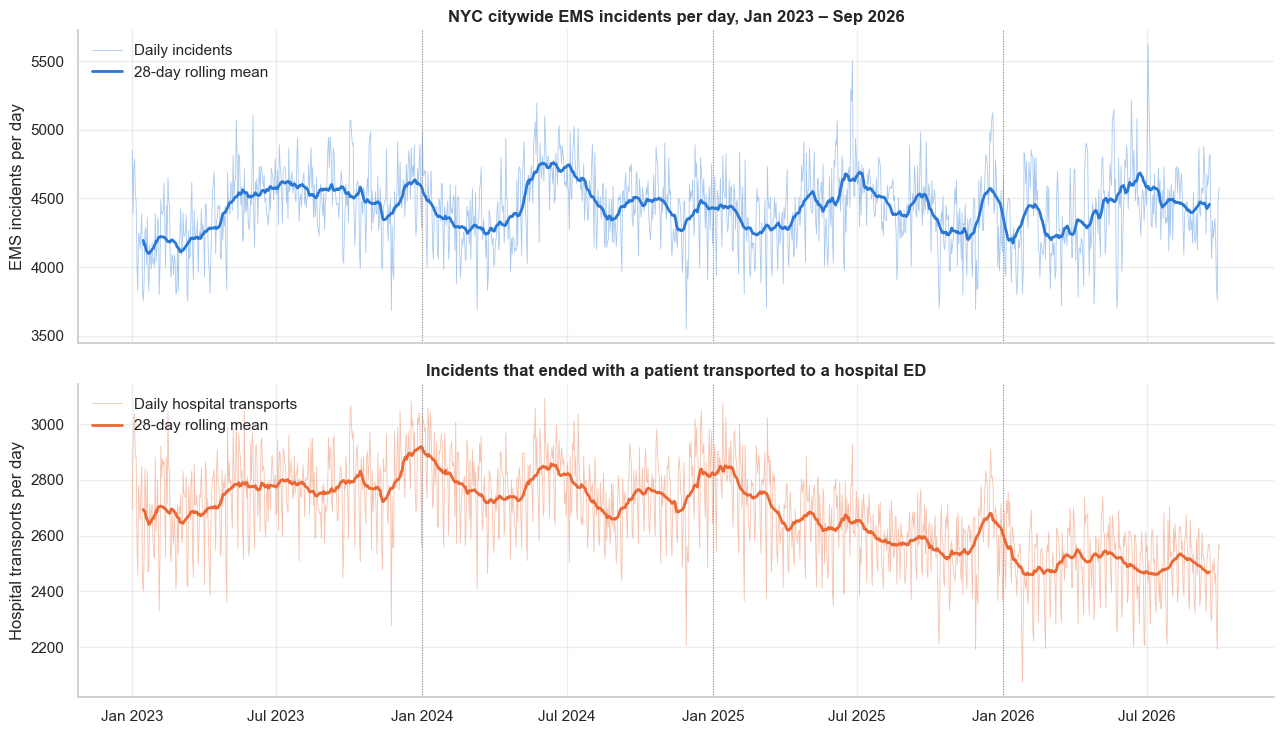

In [12]:
# Two stacked panels sharing the x-axis: total incidents on top, hospital transports below
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)

ax = axes[0]
ax.plot(df.index, df[y_col], color=BLUE, lw=0.6, alpha=0.4, label='Daily incidents')
ax.plot(df.index, df[y_col].rolling(28, center=True).mean(), color=BLUE, lw=2, label='28-day rolling mean')
ax.set_ylabel('EMS incidents per day')
ax.set_title('NYC citywide EMS incidents per day, Jan 2023 – Sep 2026')
ax.legend(loc='upper left', frameon=False)

ax = axes[1]
ax.plot(df.index, df['hospital_transports'], color=ORANGE, lw=0.6, alpha=0.4, label='Daily hospital transports')
ax.plot(df.index, df['hospital_transports'].rolling(28, center=True).mean(), color=ORANGE, lw=2, label='28-day rolling mean')
ax.set_ylabel('Hospital transports per day')
ax.set_title('Incidents that ended with a patient transported to a hospital ED')
ax.legend(loc='upper left', frameon=False)

for ax in axes:
    for yr in range(2024, 2027):
        ax.axvline(pd.Timestamp(f'{yr}-01-01'), color='grey', lw=0.7, ls=':')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/01_daily_incidents_timeseries.png', bbox_inches='tight')
plt.show()

**Observations.** Demand is remarkably stable at roughly 4,400 incidents per day with **no trend** across the period: the yearly means for 2023, 2024, 2025 and 2026 are all within 1% of each other. On top of that flat level sits a clear **annual cycle** (early-summer peaks, late-winter troughs, a smaller bump each December) and a fine weekly texture. Hospital transports follow the same shape at about 60% of incidents, with the gradual decline from mid-2025 noted in Section 2. There are no structural breaks, which is what makes this a representative window for forecasting.

### 4.2 Distribution of the target variable

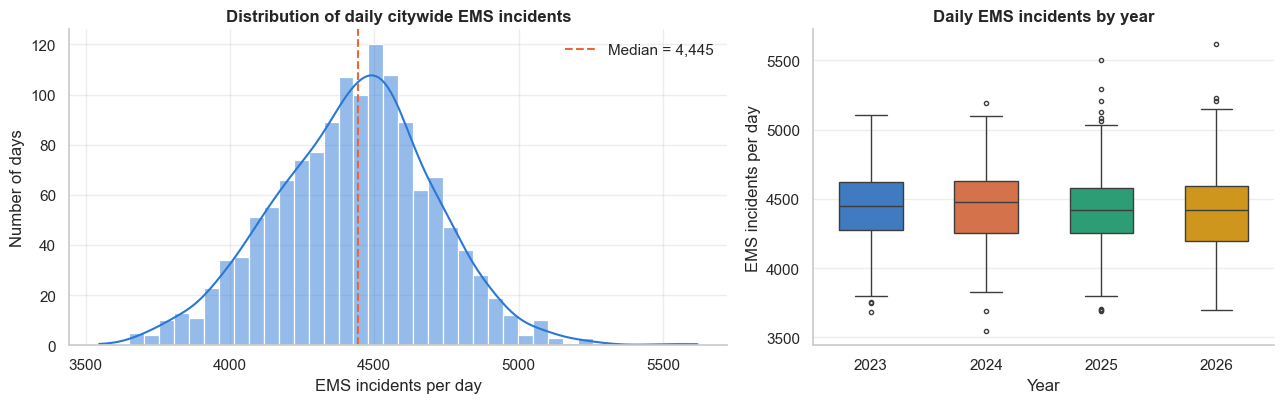

,count,mean,median,std,min,max
year,,,,,,
2023,365,4432.0,4450.0,274.0,3685,5106
2024,366,4455.0,4476.0,262.0,3547,5195
2025,365,4417.0,4416.0,273.0,3689,5502
2026,273,4412.0,4422.0,303.0,3700,5620


In [13]:
# Histogram + KDE for the overall shape, boxplots by year to check for level shifts
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [2, 1.4]})

sns.histplot(df[y_col], bins=40, kde=True, color=BLUE, ax=axes[0])
axes[0].axvline(df[y_col].median(), color=ORANGE, ls='--', lw=1.5, label=f'Median = {df[y_col].median():,.0f}')
axes[0].set_xlabel('EMS incidents per day')
axes[0].set_ylabel('Number of days')
axes[0].set_title('Distribution of daily citywide EMS incidents')
axes[0].legend(frameon=False)

sns.boxplot(data=df.reset_index(), x='year', y=y_col, hue='year', palette=PALETTE[:4], legend=False,
            width=0.55, fliersize=3, ax=axes[1])
axes[1].set_xlabel('Year')
axes[1].set_ylabel('EMS incidents per day')
axes[1].set_title('Daily EMS incidents by year')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/02_target_distribution.png', bbox_inches='tight')
plt.show()

df.groupby('year')[y_col].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(0)

**Observations.** Daily volume is close to symmetric and bell-shaped around ~4,450 incidents, with a standard deviation of under 300 (about 6% of the mean). The yearly distributions are almost interchangeable, so there is no level shift for a model to chase. Compared with the pandemic-era ED series, this target is far better behaved. (2026 covers January–September only.)

### 4.3 Calendar seasonality: day of week and month

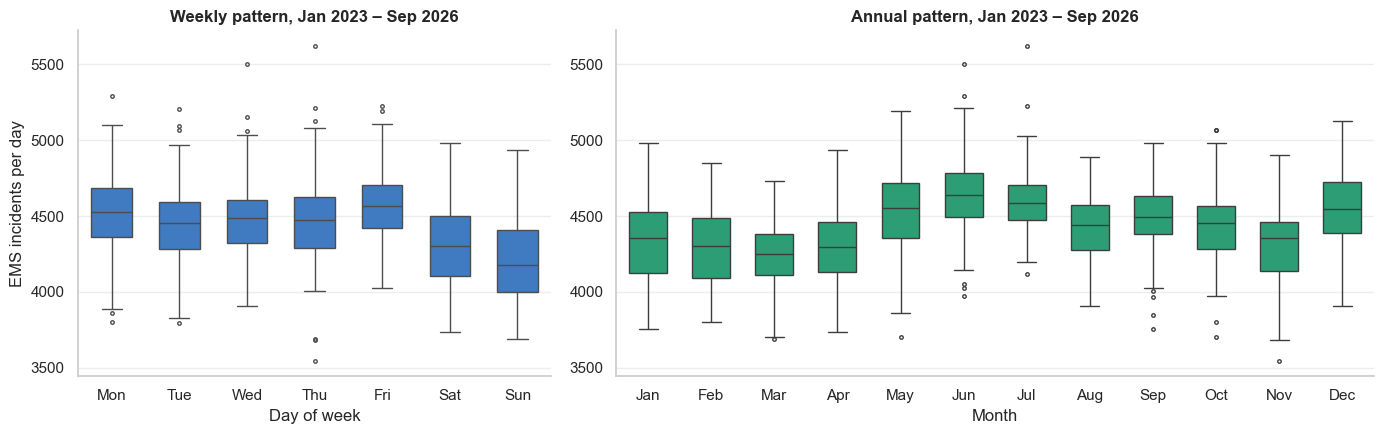

Mean incidents by day of week:
dow_name
Mon    4516.0
Tue    4459.0
Wed    4483.0
Thu    4474.0
Fri    4569.0
Sat    4307.0
Sun    4204.0

Friday vs. Sunday gap: 365 incidents (9% higher on Friday)
June vs. March gap   : 400 incidents (9% higher in June)


In [14]:
# Boxplots are appropriate here: a continuous target split by two categorical calendar variables
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [1, 1.6]})
dow_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

sns.boxplot(data=df, x='dow_name', y=y_col, order=dow_order, color=BLUE, width=0.6, fliersize=2.5, ax=axes[0])
axes[0].set_xlabel('Day of week')
axes[0].set_ylabel('EMS incidents per day')
axes[0].set_title('Weekly pattern, Jan 2023 – Sep 2026')

sns.boxplot(data=df, x='month', y=y_col, color=AQUA, width=0.6, fliersize=2.5, ax=axes[1])
axes[1].set_xticks(range(12))
axes[1].set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
axes[1].set_xlabel('Month')
axes[1].set_ylabel('')
axes[1].set_title('Annual pattern, Jan 2023 – Sep 2026')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/03_dow_month_boxplots.png', bbox_inches='tight')
plt.show()

dow_means = df.groupby('dow_name')[y_col].mean().reindex(dow_order).round(0)
month_means = df.groupby('month')[y_col].mean().round(0)
print('Mean incidents by day of week:')
print(dow_means.to_string())
print(f'\nFriday vs. Sunday gap: {dow_means["Fri"] - dow_means["Sun"]:,.0f} incidents '
      f'({100 * (dow_means["Fri"] / dow_means["Sun"] - 1):.0f}% higher on Friday)')
print(f'June vs. March gap   : {month_means[6] - month_means[3]:,.0f} incidents '
      f'({100 * (month_means[6] / month_means[3] - 1):.0f}% higher in June)')

**Observations.** Unlike hospital ED visits, EMS demand does not spike on Mondays: weekdays are flat with a small Friday high, and **Sundays are the quietest day** (about 9% below Friday). The **annual cycle is at least as strong as the weekly one**: June runs roughly 9% above March, consistent with heat-related illness, outdoor injuries and more people out and about in summer, and December shows a secondary bump that lines up with respiratory-illness season.

### 4.4 Holiday effects

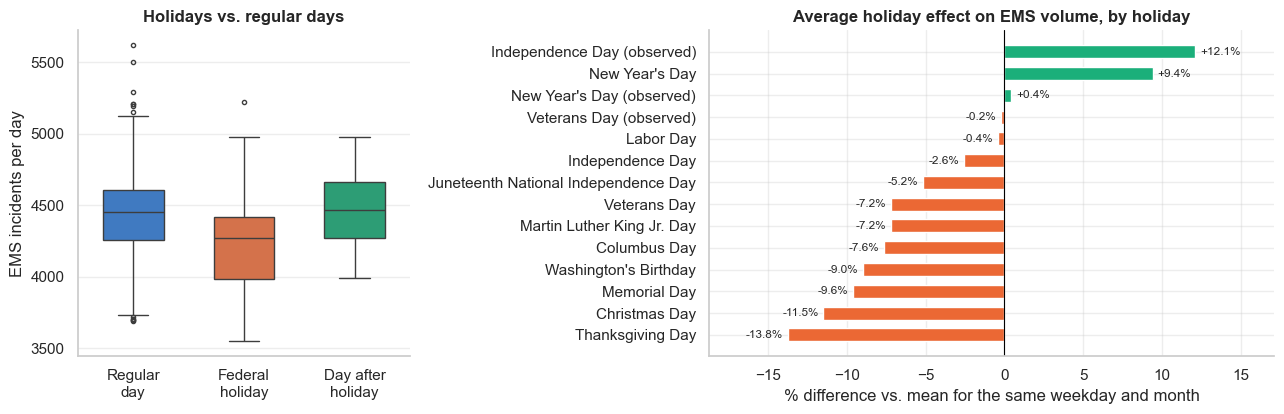

,count,mean,median
day_type,,,
Regular day,1286,4435.0,4450.0
Federal holiday,43,4253.0,4274.0
Day after holiday,40,4472.0,4464.0


In [15]:
tmp = df.copy()
tmp['day_type'] = np.select(
    [tmp['is_holiday'] == 1, tmp['day_after_holiday'] == 1],
    ['Federal holiday', 'Day after holiday'], default='Regular day')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={'width_ratios': [1, 1.7]})
order = ['Regular day', 'Federal holiday', 'Day after holiday']
sns.boxplot(data=tmp, x='day_type', y=y_col, order=order, hue='day_type', hue_order=order,
            palette=[BLUE, ORANGE, AQUA], legend=False, width=0.55, fliersize=3, ax=axes[0])
axes[0].set_xticks(range(3))
axes[0].set_xticklabels(['Regular\nday', 'Federal\nholiday', 'Day after\nholiday'])
axes[0].set_xlabel('')
axes[0].set_ylabel('EMS incidents per day')
axes[0].set_title('Holidays vs. regular days')

# Per-holiday deviation from the mean of the same weekday *and month*, so weekday and season don't confound it
ref_mean = tmp.groupby(['dow', 'month'])[y_col].transform('mean')
tmp['pct_vs_ref'] = 100 * (tmp[y_col] / ref_mean - 1)
hol = tmp[tmp['is_holiday'] == 1].groupby('holiday_name')['pct_vs_ref'].mean().sort_values()
colors = [ORANGE if v < 0 else AQUA for v in hol.values]
axes[1].barh(hol.index, hol.values, color=colors, height=0.6)
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set_xlabel('% difference vs. mean for the same weekday and month')
axes[1].set_title('Average holiday effect on EMS volume, by holiday')
for i, v in enumerate(hol.values):
    axes[1].text(v + (0.3 if v >= 0 else -0.3), i, f'{v:+.1f}%', va='center',
                 ha='left' if v >= 0 else 'right', fontsize=8.5)
axes[1].set_xlim(min(hol.min(), 0) - 5, max(hol.max(), 0) + 5)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/04_holiday_effects.png', bbox_inches='tight')
plt.show()

tmp.groupby('day_type')[y_col].agg(['count', 'mean', 'median']).round(0).reindex(order)

**Observations.** Holidays pull in both directions, which is why a single "holiday" flag is only a first approximation. Thanksgiving and Christmas Day are the quietest days of the year (people stay home, roughly 12–14% below a comparable day), and most Monday holidays are 7–10% quiet, whereas **New Year's Day and the observed Independence Day are busy** (celebrations, alcohol, fireworks; +9% to +12%). The day after a holiday is slightly above a regular day. In Module 24 it will be worth giving the biggest holidays their own indicators.

### 4.5 Weather and EMS demand

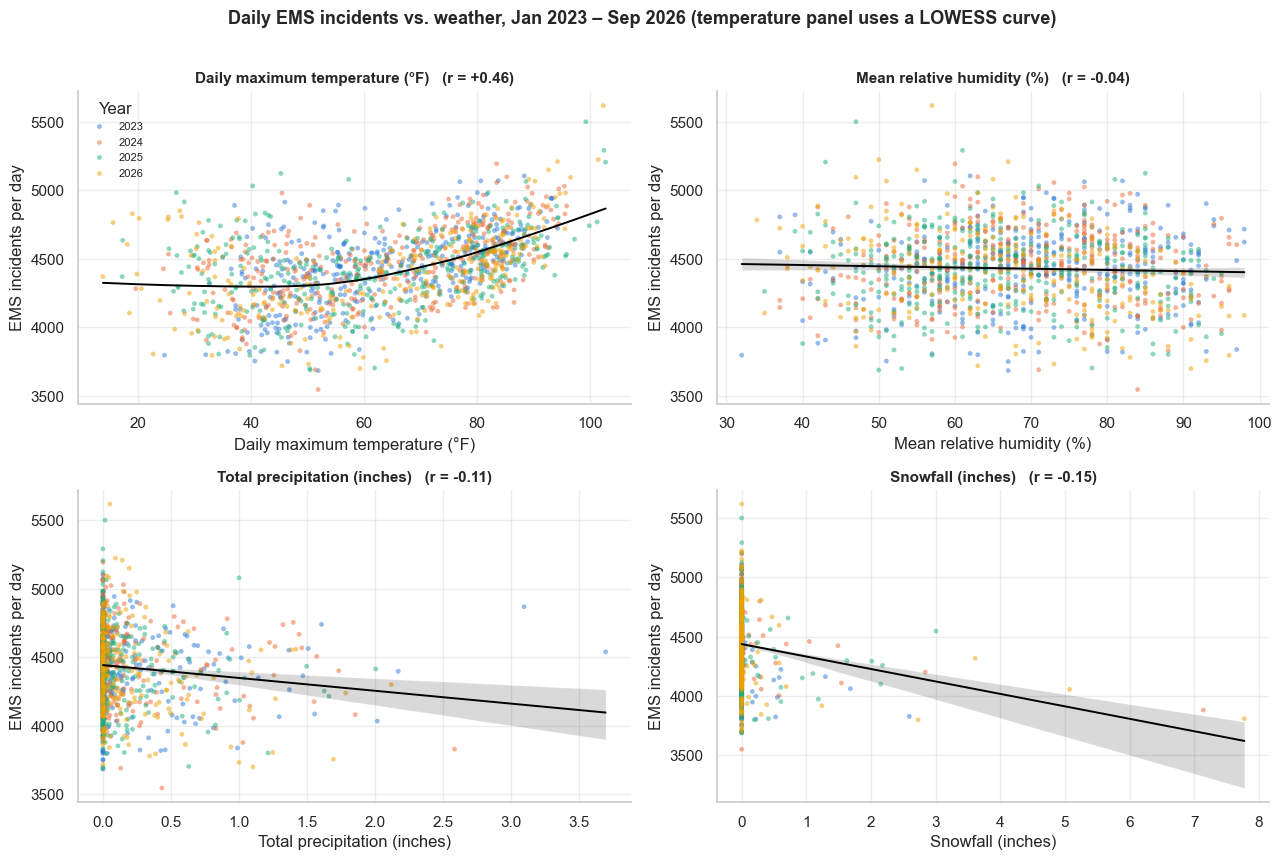

,days,mean incidents (flag=1),mean incidents (flag=0),difference
condition,,,,
Hot day (max ≥ 90°F),70,4790,4411,380
Freezing day (min ≤ 32°F),294,4326,4459,-133
Heavy precipitation (≥ 0.5 in),134,4333,4441,-108
Snow day (≥ 1 in),20,4132,4435,-303


In [16]:
plot_df = df.reset_index()
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
pairs = [('temp_max_f', 'Daily maximum temperature (°F)'),
         ('humidity_pct', 'Mean relative humidity (%)'),
         ('precip_in', 'Total precipitation (inches)'),
         ('snow_in', 'Snowfall (inches)')]
for ax, (col, label) in zip(axes.ravel(), pairs):
    sns.scatterplot(data=plot_df, x=col, y=y_col, hue='year', palette=PALETTE[:4], s=12, alpha=0.5,
                    edgecolor='none', ax=ax, legend=(col == 'temp_max_f'))
    sns.regplot(data=plot_df, x=col, y=y_col, scatter=False, color='black',
                lowess=(col == 'temp_max_f'), line_kws={'lw': 1.4}, ax=ax)
    r = plot_df[[col, y_col]].corr().iloc[0, 1]
    ax.set_title(f'{label}   (r = {r:+.2f})', fontsize=11)
    ax.set_xlabel(label)
    ax.set_ylabel('EMS incidents per day')
axes[0, 0].legend(title='Year', frameon=False, loc='upper left', fontsize=8)
fig.suptitle('Daily EMS incidents vs. weather, Jan 2023 – Sep 2026 (temperature panel uses a LOWESS curve)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/05_weather_scatter.png', bbox_inches='tight')
plt.show()

# Extreme-weather flags: mean incidents on flagged vs. unflagged days
rows = []
for flag, label in [('hot_day', 'Hot day (max ≥ 90°F)'), ('freezing_day', 'Freezing day (min ≤ 32°F)'),
                    ('heavy_precip', 'Heavy precipitation (≥ 0.5 in)'), ('snow_day', 'Snow day (≥ 1 in)')]:
    g = df.groupby(flag)[y_col].mean()
    rows.append({'condition': label, 'days': int(df[flag].sum()),
                 'mean incidents (flag=1)': round(g[1]), 'mean incidents (flag=0)': round(g[0]),
                 'difference': round(g[1] - g[0])})
pd.DataFrame(rows).set_index('condition')

**Observations.** Temperature is the single strongest exogenous driver (r ≈ +0.46): demand climbs with heat and the LOWESS curve steepens above ~85°F, so the 70 hot days average almost 400 more incidents than other days. The curve also **turns up again at the cold extreme** (below ~25°F), a hint that bitter cold raises demand even though mild cold lowers it; a linear temperature term cannot capture that U-shape. Snow days are quiet (people stay off the roads), and rain and wind have small negative effects. Because temperature and season move together, the regression needs both month dummies and temperature to separate them.

### 4.6 Correlation structure

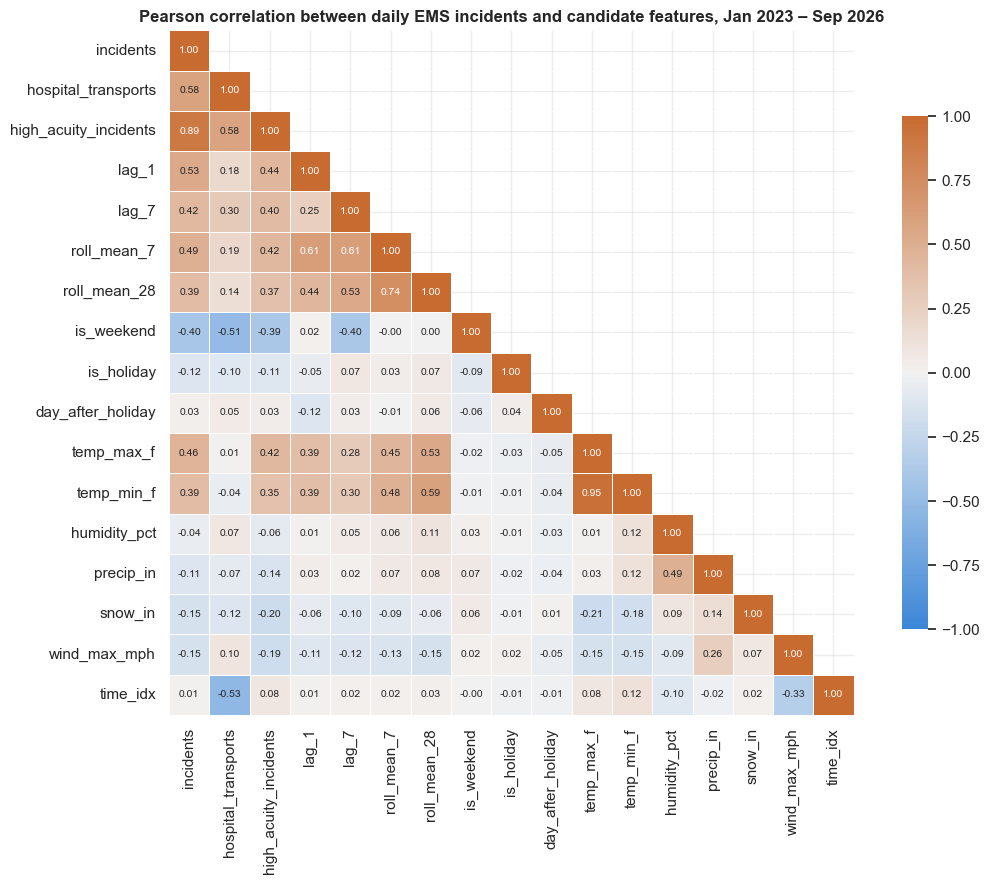

Correlation with daily incidents (sorted):
lag_1                0.526
roll_mean_7          0.489
temp_max_f           0.460
lag_7                0.416
roll_mean_28         0.393
temp_min_f           0.393
day_after_holiday    0.027
time_idx             0.011
humidity_pct        -0.044
precip_in           -0.114
is_holiday          -0.116
snow_in             -0.151
wind_max_mph        -0.152
is_weekend          -0.400


In [17]:
corr_cols = [y_col, 'hospital_transports', 'high_acuity_incidents', 'lag_1', 'lag_7', 'roll_mean_7', 'roll_mean_28',
             'is_weekend', 'is_holiday', 'day_after_holiday', 'temp_max_f', 'temp_min_f', 'humidity_pct',
             'precip_in', 'snow_in', 'wind_max_mph', 'time_idx']
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11.5, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
cmap = sns.diverging_palette(250, 30, l=55, s=85, as_cmap=True)     # blue – gray – orange
sns.heatmap(corr, mask=mask, cmap=cmap, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
            annot_kws={'size': 7.5}, square=True, linewidths=0.5, cbar_kws={'shrink': 0.75}, ax=ax)
ax.set_title('Pearson correlation between daily EMS incidents and candidate features, Jan 2023 – Sep 2026')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/06_correlation_heatmap.png', bbox_inches='tight')
plt.show()

print('Correlation with daily incidents (sorted):')
print(corr[y_col].drop([y_col, 'hospital_transports', 'high_acuity_incidents']).sort_values(ascending=False).round(3).to_string())

**Observations.** The trailing means and lags are the most correlated with today's volume (r ≈ 0.6–0.7), followed by maximum temperature (≈ 0.46). The time index is essentially uncorrelated with volume, confirming the absence of a trend. The weekend flag matters less than in hospital data. Hospital transports and high-acuity incidents are highly correlated with total incidents, so they are reported for context but not used as predictors (they are not known in advance).

### 4.7 Autocorrelation: weekly and annual memory

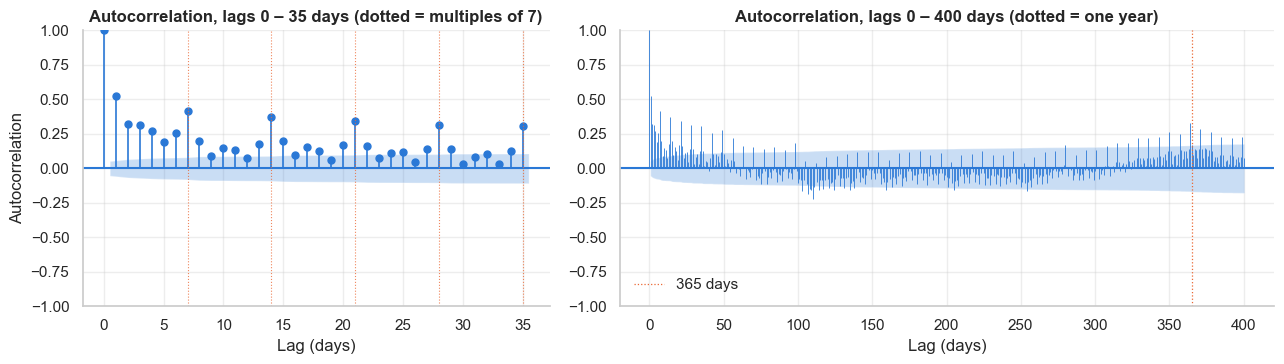

In [18]:
# Short-lag ACF reveals the weekly cycle; long-lag ACF reveals the annual cycle
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [1, 1.4]})
plot_acf(df[y_col], lags=35, ax=axes[0], color=BLUE, vlines_kwargs={'colors': BLUE, 'lw': 1.2})
for lag in (7, 14, 21, 28, 35):
    axes[0].axvline(lag, color=ORANGE, lw=0.8, ls=':', alpha=0.8)
axes[0].set_title('Autocorrelation, lags 0 – 35 days (dotted = multiples of 7)')
axes[0].set_xlabel('Lag (days)')
axes[0].set_ylabel('Autocorrelation')

plot_acf(df[y_col], lags=400, ax=axes[1], color=BLUE, marker=None, vlines_kwargs={'colors': BLUE, 'lw': 0.6})
axes[1].axvline(365, color=ORANGE, lw=0.9, ls=':', label='365 days')
axes[1].set_title('Autocorrelation, lags 0 – 400 days (dotted = one year)')
axes[1].set_xlabel('Lag (days)')
axes[1].legend(frameon=False)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/07_autocorrelation.png', bbox_inches='tight')
plt.show()

**Observations.** The left panel shows bumps at every multiple of 7 days (weekly cycle) riding on a slowly decaying base (persistence of the seasonal level). The right panel shows autocorrelation falling to a minimum around six months and recovering toward a year, the signature of the annual cycle. Yesterday's value and the same weekday last week are therefore both natural benchmarks, and the slow decay suggests a trailing mean will be a strong predictor.

### 4.8 Geography and call mix (context from the raw data)

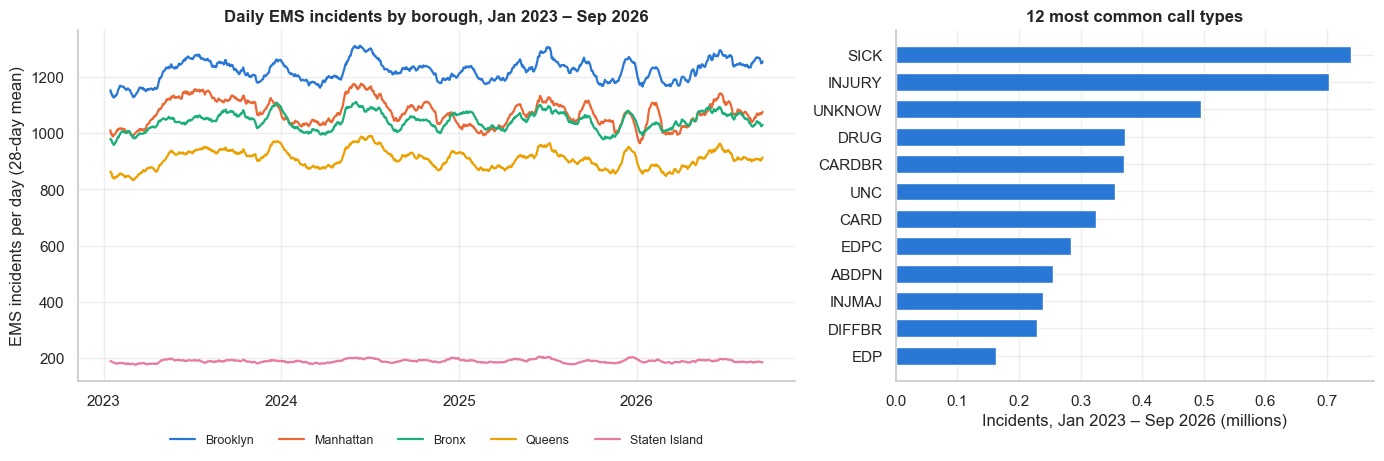

Share of incidents by borough:
borough
Brooklyn         27.6
Manhattan        24.2
Bronx            23.5
Queens           20.5
Staten Island     4.3


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.5, 1]})

# Left: 28-day rolling mean of daily incidents per borough – one hue per borough, fixed order
boro_order = ['Brooklyn', 'Manhattan', 'Bronx', 'Queens', 'Staten Island']
boro_wide = boro.pivot(index='date', columns='borough', values='incidents')[boro_order]
boro_wide = boro_wide[boro_wide.index >= '2023-01-01']
for color, b in zip(PALETTE, boro_order):
    axes[0].plot(boro_wide.index, boro_wide[b].rolling(28, center=True).mean(), color=color, lw=1.6, label=b)
axes[0].set_ylabel('EMS incidents per day (28-day mean)')
axes[0].set_title('Daily EMS incidents by borough, Jan 2023 – Sep 2026')
axes[0].legend(frameon=False, ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.12), fontsize=9)
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Right: top 12 final call types for the whole period
top = calltype.head(12).iloc[::-1]
axes[1].barh(top['final_call_type'], top['incidents'] / 1e6, color=BLUE, height=0.65)
axes[1].set_xlabel('Incidents, Jan 2023 – Sep 2026 (millions)')
axes[1].set_title('12 most common call types')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/08_borough_calltype.png', bbox_inches='tight')
plt.show()

boro_share = boro[boro['date'] >= '2023-01-01'].groupby('borough')['incidents'].sum()
print('Share of incidents by borough:')
print((100 * boro_share / boro_share.sum()).round(1).sort_values(ascending=False).to_string())

**Observations.** Brooklyn generates about 28% of citywide demand, Manhattan and the Bronx roughly a quarter each, Queens a fifth, and Staten Island under 5%. All five boroughs share the same summer-high / winter-low rhythm, which supports modeling the citywide total first and disaggregating later. The call mix is dominated by generic "sick" and "injury" calls, followed by unknown-condition, drug-related and cardiac/breathing calls.

### 4.9 Outlier analysis

Two complementary checks:
1. **Global IQR rule** on the daily series – days that are extreme relative to the whole period.
2. **Local anomaly score** – the deviation of each day from a centered 15-day rolling median, scaled by the rolling MAD. This flags days that are unusual *for their own season*.

In [20]:
# Global rule: Tukey fences at 1.5 x IQR on the whole series
s = df[y_col]
q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr

# Local rule: robust z-score of each day against a centered 15-day window (median / MAD)
roll_med = s.rolling(15, center=True, min_periods=8).median()
roll_mad = (s - roll_med).abs().rolling(15, center=True, min_periods=8).median()
df['local_z'] = 0.6745 * (s - roll_med) / roll_mad
local_out = df[df['local_z'].abs() > 3.5]
global_out = df[(s < lo) | (s > hi)]

print(f'IQR bounds: [{lo:,.0f}, {hi:,.0f}]  ->  {len(global_out)} global outliers')
print(f'Local robust z-score |z| > 3.5  ->  {len(local_out)} local anomalies\n')

cols = [y_col, 'dow_name', 'holiday_name', 'temp_max_f', 'snow_in', 'local_z']
print('Global outliers:')
display(global_out[cols].sort_values(y_col).round(1))
# Show only the 10 strongest local anomalies that the IQR rule did not already catch
print('Strongest local anomalies not already in the global list (top 10 by |z|):')
extra = local_out.loc[~local_out.index.isin(global_out.index), cols]
extra.reindex(extra['local_z'].abs().sort_values(ascending=False).index).head(10).round(1)

IQR bounds: [3,714, 5,142]  ->  15 global outliers
Local robust z-score |z| > 3.5  ->  26 local anomalies

Global outliers:


,incidents,dow_name,holiday_name,temp_max_f,snow_in,local_z
date,,,,,,
2024-11-28,3547,Thu,Thanksgiving Day,51.9,0.0,-3.3
2023-11-23,3685,Thu,Thanksgiving Day,51.9,0.0,-5.1
2025-11-27,3689,Thu,Thanksgiving Day,50.5,0.0,-2.2
2024-03-10,3691,Sun,None,51.4,0.0,-3.6
2025-03-09,3700,Sun,None,50.4,0.0,-2.8
2026-05-24,3700,Sun,None,59.3,0.0,-1.7
2025-10-12,3704,Sun,None,61.9,0.0,-2.7
2026-05-20,5151,Wed,None,92.7,0.0,1.5
2024-05-24,5195,Fri,None,83.5,0.0,2.9


Strongest local anomalies not already in the global list (top 10 by |z|):


,incidents,dow_name,holiday_name,temp_max_f,snow_in,local_z
date,,,,,,
2024-01-12,4702,Fri,None,46.7,0.0,8.5
2023-11-11,4006,Sat,Veterans Day,53.5,0.0,-6.5
2025-09-05,4889,Fri,None,83.1,0.0,6.0
2023-02-04,3798,Sat,None,24.7,0.0,-4.9
2024-03-23,3830,Sat,None,48.7,0.0,-4.9
2024-08-04,4146,Sun,None,82.9,0.0,-4.8
2026-03-15,3720,Sun,None,45.5,0.0,-4.5
2023-07-09,4321,Sun,None,80.6,0.0,-4.4
2023-04-02,3925,Sun,None,50.5,0.0,-4.3


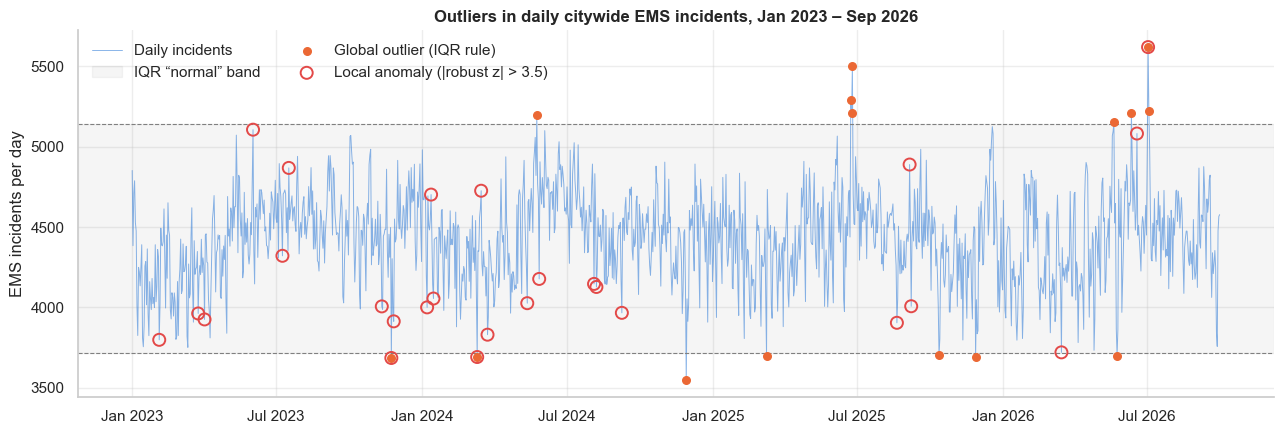

In [21]:
# Plot the series with the IQR band and highlight both kinds of flagged days
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(df.index, s, color=BLUE, lw=0.7, alpha=0.55, label='Daily incidents')
ax.axhspan(lo, hi, color='grey', alpha=0.08, label='IQR “normal” band')
ax.axhline(lo, color='grey', lw=0.8, ls='--')
ax.axhline(hi, color='grey', lw=0.8, ls='--')
ax.scatter(global_out.index, global_out[y_col], color=ORANGE, s=30, zorder=3, label='Global outlier (IQR rule)')
ax.scatter(local_out.index, local_out[y_col], facecolors='none', edgecolors=RED, s=75, lw=1.4, zorder=4,
           label='Local anomaly (|robust z| > 3.5)')
ax.set_ylabel('EMS incidents per day')
ax.set_title('Outliers in daily citywide EMS incidents, Jan 2023 – Sep 2026')
ax.legend(frameon=False, loc='upper left', ncol=2)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/09_outliers.png', bbox_inches='tight')
plt.show()

**Decision.** Every flagged day has a real-world explanation. The low outliers are the **three Thanksgiving Days** and a handful of quiet spring and autumn Sundays; the high outliers are **early-summer heat waves** (the late-June 2025 heat dome, 2 July 2026 at 102°F) and the Friday of Memorial Day weekend 2024. None is a recording error, and all are the kind of day an operations team most needs to anticipate, so **no observations are removed**. Instead, the holiday and weather features are expected to explain them, and the residual analysis in Section 5 checks whether they do.

## 5. Baseline model

### Evaluation metric
The target is a daily count used for ambulance and crew scheduling. Three metrics are reported, with one designated as primary:

* **MAE (mean absolute error) – primary.** It is in the same units as the target (incidents per day) and reads directly as "on a typical day the forecast is off by X calls." Crew-hours wasted or short are roughly proportional to the miss, so MAE matches the operational cost.
* **RMSE (root mean squared error).** Penalises large misses more heavily; the RMSE/MAE ratio shows whether errors are concentrated in a few bad days.
* **MAPE (mean absolute percentage error).** Scale-free, so results can be compared with other cities or with borough-level models later.

### Validation design
Because the data are a time series, a **time-ordered split** is used instead of a random one (a random split would leak future information through the lag features). The first 33 months (January 2023 – September 2025, 1,004 days) are used for training and the **most recent 12 months (October 2025 – September 2026, 365 days) are held out** for testing, so the test set contains every season and every holiday once and reflects the most current operating conditions.

### Models
1. **Seasonal-naive benchmarks** – "same weekday last week" and "yesterday". Not ML, but the bar any model must clear.
2. **Model A – Linear regression on calendar + weather + trend.** How far do exogenous factors alone get us?
3. **Model B – Linear regression on calendar + weather + lag features.** The baseline carried into Module 24.

In [22]:
# One-hot encode day of week and month (drop_first avoids perfect collinearity with the intercept)
model_df = pd.get_dummies(df, columns=['dow', 'month'], prefix=['dow', 'month'], drop_first=True, dtype=int)

calendar_feats = [c for c in model_df.columns if c.startswith(('dow_', 'month_')) and c != 'dow_name'] \
                 + ['is_holiday', 'day_after_holiday']
weather_feats  = ['temp_max_f', 'temp_min_f', 'precip_in', 'snow_in', 'wind_max_mph', 'humidity_pct',
                  'hot_day', 'freezing_day', 'heavy_precip', 'snow_day']
lag_feats      = ['lag_1', 'lag_7', 'lag_14', 'roll_mean_7', 'roll_mean_28']

feature_sets = {
    'Model A: calendar + weather + trend': calendar_feats + weather_feats + ['time_idx'],
    'Model B: calendar + weather + lags' : calendar_feats + weather_feats + lag_feats,
}

split_date = '2025-10-01'
train = model_df[model_df.index <  split_date]
test  = model_df[model_df.index >= split_date]
print(f'Train: {train.index.min().date()} to {train.index.max().date()}  ({len(train)} days)')
print(f'Test : {test.index.min().date()} to {test.index.max().date()}  ({len(test)} days)')

Train: 2023-01-01 to 2025-09-30  (1004 days)
Test : 2025-10-01 to 2026-09-30  (365 days)


In [23]:
def evaluate(y_true, y_pred):
    # Returns the three evaluation metrics as a dict
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = 100 * np.mean(np.abs((y_true - y_pred) / y_true))
    return {'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape}

results, predictions, models = {}, {}, {}

# Benchmarks that use no fitted parameters
predictions['Benchmark: naive (yesterday)']          = test['lag_1']
predictions['Benchmark: seasonal naive (last week)'] = test['lag_7']

# Linear regression models
for name, feats in feature_sets.items():
    lr = LinearRegression().fit(train[feats], train[y_col])
    predictions[name] = pd.Series(lr.predict(test[feats]), index=test.index)
    models[name] = (lr, feats)

for name, pred in predictions.items():
    results[name] = evaluate(test[y_col], pred)

results_df = pd.DataFrame(results).T.round(1)
results_df

,MAE,RMSE,MAPE (%)
Benchmark: naive (yesterday),218.1,282.4,5.0
Benchmark: seasonal naive (last week),274.4,350.9,6.3
Model A: calendar + weather + trend,177.1,234.9,4.0
Model B: calendar + weather + lags,143.9,194.8,3.3


### Interpreting the results

In [24]:
# Pull the headline numbers out of the results table for the write-up
best = results_df['MAE'].idxmin()
sn   = 'Benchmark: seasonal naive (last week)'
ma   = 'Model A: calendar + weather + trend'
print(f'Best model by MAE: {best}')
print(f'  MAE  = {results_df.loc[best, "MAE"]:,.0f} incidents/day  '
      f'(seasonal naive {results_df.loc[sn, "MAE"]:,.0f}, Model A {results_df.loc[ma, "MAE"]:,.0f}; '
      f'improvement vs. seasonal naive {100 * (1 - results_df.loc[best, "MAE"] / results_df.loc[sn, "MAE"]):.0f}%)')
print(f'  MAPE = {results_df.loc[best, "MAPE (%)"]:.1f}%  ->  the forecast is typically within '
      f'{results_df.loc[best, "MAPE (%)"]:.1f}% of actual daily volume')
print(f'  RMSE / MAE = {results_df.loc[best, "RMSE"] / results_df.loc[best, "MAE"]:.2f}')
print(f'  Test-period mean volume = {test[y_col].mean():,.0f} incidents/day')

Best model by MAE: Model B: calendar + weather + lags
  MAE  = 144 incidents/day  (seasonal naive 274, Model A 177; improvement vs. seasonal naive 48%)
  MAPE = 3.3%  ->  the forecast is typically within 3.3% of actual daily volume
  RMSE / MAE = 1.35
  Test-period mean volume = 4,395 incidents/day


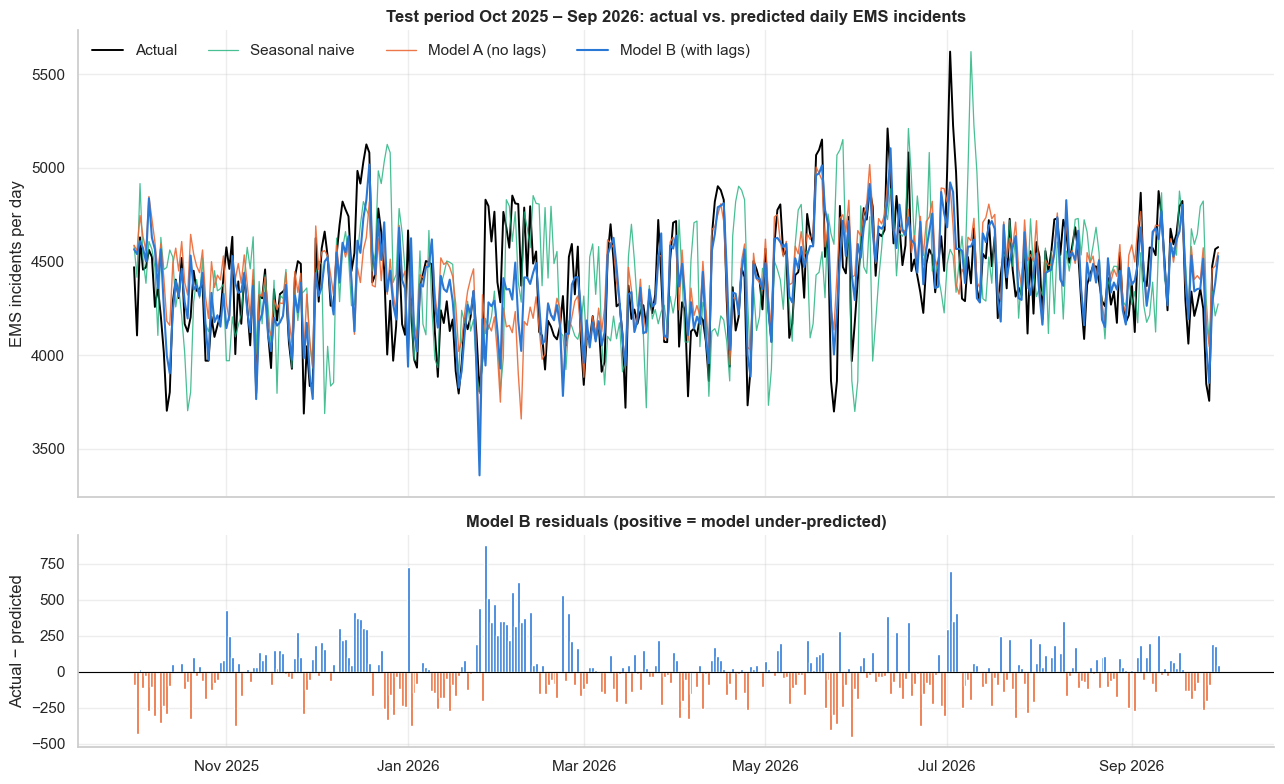

,incidents,dow_name,holiday_name,temp_max_f,snow_in,predicted,residual
date,,,,,,,
2026-02-22,4316,Sun,None,36.5,3.610,3783.0,533.0
2026-02-05,4852,Thu,None,27.4,0.000,4297.0,555.0
2026-02-07,4807,Sat,None,25.4,0.303,4184.0,623.0
2026-07-02,5620,Thu,None,102.4,0.000,4922.0,698.0
2026-01-01,4666,Thu,New Year's Day,33.1,0.469,3939.0,727.0
2026-01-27,4830,Tue,None,19.0,0.028,3945.0,885.0


In [25]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})

ax = axes[0]
ax.plot(test.index, test[y_col], color='black', lw=1.4, label='Actual')
ax.plot(test.index, predictions[sn], color=AQUA, lw=0.9, alpha=0.8, label='Seasonal naive')
ax.plot(test.index, predictions[ma], color=ORANGE, lw=1.0, alpha=0.9, label='Model A (no lags)')
ax.plot(test.index, predictions[best], color=BLUE, lw=1.5, label='Model B (with lags)')
ax.set_ylabel('EMS incidents per day')
ax.set_title('Test period Oct 2025 – Sep 2026: actual vs. predicted daily EMS incidents')
ax.legend(frameon=False, ncol=4, loc='upper left')

ax = axes[1]
resid = test[y_col] - predictions[best]
ax.bar(test.index, resid, color=np.where(resid >= 0, BLUE, ORANGE), width=1.0)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('Actual − predicted')
ax.set_title('Model B residuals (positive = model under-predicted)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/10_test_predictions.png', bbox_inches='tight')
plt.show()

# Which days does Model B miss most?
worst = resid.abs().sort_values(ascending=False).head(6).index
(df.loc[worst, [y_col, 'dow_name', 'holiday_name', 'temp_max_f', 'snow_in']]
   .assign(predicted=predictions[best][worst].round(0), residual=resid[worst].round(0))
   .sort_values('residual'))

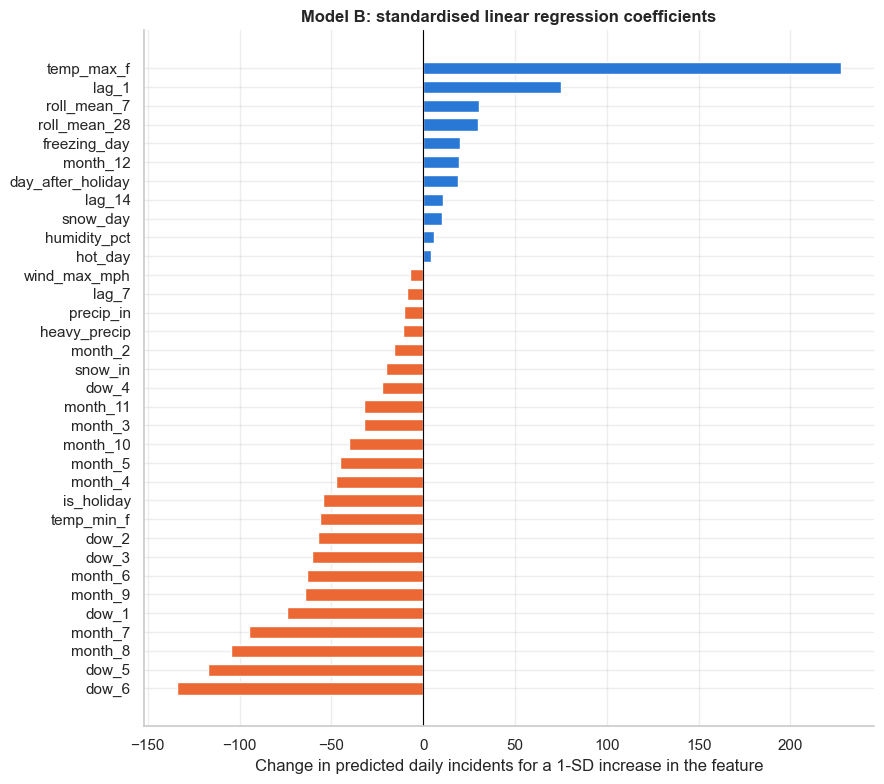

Largest effects (incidents per day, per 1-SD change):
temp_max_f    227.0
dow_6        -134.0
dow_5        -117.0
month_8      -105.0
month_7       -95.0
lag_1          75.0
dow_1         -74.0
month_9       -64.0
month_6       -63.0
dow_3         -60.0


In [26]:
# Standardised coefficients for Model B so features on different scales are comparable
lr_b, feats_b = models[best]
std_coef = pd.Series(lr_b.coef_ * train[feats_b].std().values, index=feats_b).sort_values()

fig, ax = plt.subplots(figsize=(9, 8))
colors = [ORANGE if v < 0 else BLUE for v in std_coef.values]
ax.barh(std_coef.index, std_coef.values, color=colors, height=0.65)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Change in predicted daily incidents for a 1-SD increase in the feature')
ax.set_title('Model B: standardised linear regression coefficients')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/11_model_b_coefficients.png', bbox_inches='tight')
plt.show()

print('Largest effects (incidents per day, per 1-SD change):')
print(std_coef.reindex(std_coef.abs().sort_values(ascending=False).index).head(10).round(0).to_string())

**Interpretation.**

* **Model B is the baseline to beat in Module 24.** With calendar, weather and recent-history features, a plain linear regression forecasts daily EMS volume over the most recent 12 months with a MAE of roughly 145 incidents on a ~4,400-incident day (MAPE about 3.3%), about one-third better than the naive "yesterday" benchmark and almost half the error of the seasonal-naive benchmark.
* **Seasonal naive is worse than plain naive here.** The weekly cycle is weak relative to day-to-day weather-driven swings, so last week's value is a poorer guess than yesterday's. Calendar and weather alone (Model A) already beat both benchmarks; the lag features add a further ~20% reduction in MAE.
* **The largest standardised coefficient is maximum temperature**, followed by the Sunday/Saturday dummies, the summer-month dummies (which offset the temperature term) and yesterday's volume, matching the EDA. Snow and precipitation have the expected negative signs.
* **The worst misses cluster in the extreme-cold spell of late January and early February 2026**, when demand jumped 500–900 above forecast on days with highs below 30°F. The linear temperature term predicts *fewer* calls in the cold, so it misses the U-shaped response seen in Section 4.5. New Year's Day 2026 (busy, but flagged as a generic holiday) and the 102°F day on 2 July 2026 are the other large misses. Non-linear temperature terms and holiday-specific indicators are therefore the first improvements to try.
* The RMSE/MAE ratio near 1.35 means errors are fairly evenly spread rather than dominated by a few catastrophic days.

## 6. Summary of findings and next steps

### What the EDA shows
1. **Demand is stable and predictable in a normal period.** Citywide EMS incidents average about 4,430 per day with a standard deviation under 300 and no trend between 2023 and 2026.
2. **The annual cycle dominates.** June runs roughly 9% above March, with a secondary December bump; maximum temperature is the strongest single exogenous driver (r ≈ +0.46), with demand accelerating above ~85°F and rising again in extreme cold.
3. **The weekly cycle is modest.** Weekdays are flat, Sundays are ~9% quieter than Fridays. Mondays are not special for EMS the way they are for hospital EDs.
4. **Holidays cut both ways.** Thanksgiving and Christmas are the quietest days of the year; New Year's Day and the observed Independence Day are among the busiest.
5. **Heat amplifies demand; snow and mild cold suppress it, but extreme cold raises it again.** The highest-volume days are June–July heat waves; the model's largest misses are a January–February 2026 cold snap.
6. **Outliers are events, not errors.** No observations were removed; the model is expected to explain them.

### Baseline model
A linear regression on calendar, weather and lag features (Model B), trained on January 2023 – September 2025 and tested on October 2025 – September 2026, achieves a **MAE of about 145 incidents/day (MAPE ≈ 3.3%)**, versus about 220 for a naive forecast, 275 for a seasonal-naive forecast and 177 for a regression without lag features.

### Next steps for Module 24
* Add **tree-based and gradient-boosted models** (Random Forest, XGBoost) to capture the U-shaped temperature effect and holiday × weekday interactions.
* Engineer **holiday-specific indicators** (New Year's, Independence Day, Thanksgiving, Christmas) and **non-linear temperature features** (heating and cooling degree-days, or a heat index) so both heat waves and cold snaps are captured.
* Try **regularised regression (Ridge/Lasso)** and Fourier terms for the annual cycle; add a same-day-last-year lag and an ILI/respiratory-season indicator for the December bump.
* Replace the single split with **rolling-origin cross-validation** and evaluate 7- and 14-day-ahead horizons, which matter more for crew scheduling.
* Extend from citywide to **borough-level** forecasts and to the **hospital-transport** subset, which is the direct feed into emergency departments.